# 과제 3 — ACT chunk_size 비교 실험

**과제 내용**: 같은 데이터셋으로 `chunk_size`만 10, 50, 100으로 바꾼 ACT 정책 3개를 학습하고, 실제 로봇에서 각각 10회씩 평가해 chunk_size가 성공률·동작의 부드러움·반응성에 주는 영향을 분석한다. chunk_size=100 정책에는 temporal ensemble을 적용해 10회 더 평가하고 결과를 비교한다. 학습된 정책 3개는 Huggingface Hub에 업로드한다.

### 실습 환경 — **LeRobot 0.6.0**
- Python 3.12 이상, PyTorch 2.7 이상이 필요하다.
- 실습 PC에는 `lerobot[all]==0.6.0`이 설치되어 있다. 개인 PC에서 하려면 같은 버전으로 설치한다.
  ```bash
  pip install "lerobot[all]==0.6.0"
  ```
  `all`에는 학습(wandb), 녹화·텔레오퍼레이션, SO-101 모터(feetech), Diffusion Policy, SmolVLA에 필요한 패키지가 모두 들어 있다. (0.6.0부터 extra 없이 `pip install lerobot`만 하면 학습·데이터셋 의존성이 빠지므로 주의)
- `lerobot-rollout`으로 녹화하는 평가 데이터셋은 이름이 **`rollout_`로 시작**해야 한다. `lerobot-record`와 `lerobot-rollout` 모두 새 데이터셋 이름 끝에 녹화 시각(`_YYYYMMDD_HHMMSS`)을 자동으로 붙이므로, 0절에는 **Hub에 실제로 올라간 이름**을 적는다.

### 작성 요령
- 이 노트북을 본인 GitHub 저장소(과제 1, 2와 같은 저장소, assignments 폴더)에 `assignment_3.ipynb`로 올린다.
- 학습과 평가는 **터미널에서** 진행하고 이 노트북에는 결과 확인 코드와 분석을 작성한다. (보고서를 노트북으로 작성하는 것이다.)
- 모든 코드 셀은 **실행한 뒤 출력 결과가 보이는 상태로** 커밋한다. (출력이 없으면 미제출로 간주)
- `[작성]` 표시가 있는 부분을 모두 채운다.

### 주의 사항
- 이번 과제는 **통제 실험**이다. 실험할 ACT 정책 3개는 `chunk_size`와 `n_action_steps`를 제외한 모든 설정(데이터셋, steps, batch_size, seed)이 같아야 한다. 1-3의 확인 셀에서 자동으로 검사한다.
- 과제 2의 정책(기본값 chunk_size=100)을 chunk_size=100 조건으로 **재사용해도 된다.** 이 경우 나머지 두 정책은 과제 2와 같은 데이터셋·steps·batch_size·seed로 학습해야 한다.
- 학습 데이터셋, 평가 데이터셋, 모델 repo는 모두 **public**으로 설정한다.
- 모델 가중치는 **Huggingface Hub에만** 올리고 GitHub에는 올리지 않는다. `.gitignore`에 `outputs/`가 있는지 확인할 것.
- **마감 시각 이후의 커밋은 반영하지 않는다.**

## 0. 제출 정보

In [4]:
# [작성] 본인 정보로 수정
STUDENT_ID = "2017136116"
NAME = "정종우"
HF_USER = "knight7024"

TASK = "pick a hair roll and place into a box"   # 과제 1에서 녹화 시 사용한 영어 task 문장 그대로

TRAIN_DATASET = f"{HF_USER}/pick_and_place_hair_roll_final"   # 세 정책이 공통으로 사용한 학습 데이터셋 (0.6.0에서 녹화했다면 끝에 녹화 시각이 붙어 있다)
CHUNK_SIZES = [10, 50, 100]

# 정책 repo (과제 2 정책을 재사용하면 100번 항목을 과제 2 repo로 바꿀 것)
POLICY_REPOS = {k: f"{HF_USER}/act_pick_and_place_hair_roll_final_chunk{k}" for k in CHUNK_SIZES}

# 평가 데이터셋 — lerobot-rollout으로 녹화, 이름은 rollout_로 시작하고 끝에 녹화 시각이 붙는다.
# Hub에 실제로 올라간 이름을 조건별로 그대로 적을 것 (과제 2 평가를 재사용하면 100번 항목에 과제 2 평가 데이터셋을 적는다)
EVAL_DATASETS = {
    10:  f"{HF_USER}/rollout_act_pick_and_place_hair_roll_final_chunk10_20261119_005310",
    50:  f"{HF_USER}/rollout_act_pick_and_place_hair_roll_final_chunk50_20261119_010607",
    100: f"{HF_USER}/rollout_act_pick_and_place_hair_roll_final_chunk100_20261119_011713",
}
WANDB_URL = ""   # 사용하지 않았다면 빈 문자열

print("학번/이름     :", STUDENT_ID, NAME)
print("태스크        :", TASK)
print("학습 데이터셋 :", f"https://huggingface.co/datasets/{TRAIN_DATASET}")
for k in CHUNK_SIZES:
    print(f"chunk{k:<4} 정책 :", f"https://huggingface.co/{POLICY_REPOS[k]}")
    print(f"chunk{k:<4} 평가 :", f"https://huggingface.co/datasets/{EVAL_DATASETS[k]}")
print("wandb         :", WANDB_URL or "(미사용)")

학번/이름     : 2017136116 정종우
태스크        : pick a hair roll and place into a box
학습 데이터셋 : https://huggingface.co/datasets/knight7024/pick_and_place_hair_roll_final
chunk10   정책 : https://huggingface.co/knight7024/act_pick_and_place_hair_roll_final_chunk10
chunk10   평가 : https://huggingface.co/datasets/knight7024/rollout_act_pick_and_place_hair_roll_final_chunk10_20261119_005310
chunk50   정책 : https://huggingface.co/knight7024/act_pick_and_place_hair_roll_final_chunk50
chunk50   평가 : https://huggingface.co/datasets/knight7024/rollout_act_pick_and_place_hair_roll_final_chunk50_20261119_010607
chunk100  정책 : https://huggingface.co/knight7024/act_pick_and_place_hair_roll_final_chunk100
chunk100  평가 : https://huggingface.co/datasets/knight7024/rollout_act_pick_and_place_hair_roll_final_chunk100_20261119_011713
wandb         : (미사용)


In [ ]:
# LeRobot 버전 확인 — 학습·평가에 사용한 환경과 같은 커널에서 실행할 것
from importlib.metadata import version, PackageNotFoundError
try:
    LEROBOT_VERSION = version("lerobot")
except PackageNotFoundError:
    LEROBOT_VERSION = None
print("lerobot 버전:", LEROBOT_VERSION or "(이 커널에 설치되어 있지 않음)")
print("버전 확인   :", "통과" if LEROBOT_VERSION and LEROBOT_VERSION.startswith("0.6.") else "0.6.x가 아님 — 실습 환경을 확인할 것")

lerobot 버전: (이 커널에 설치되어 있지 않음)
버전 확인   : 0.6.x가 아님 — 실습 환경을 확인할 것


In [6]:
# Hub 접근 확인 — 7개 repo 모두 "OK"가 나와야 한다
import json
from huggingface_hub import HfApi, hf_hub_download

api = HfApi()
checks = [(TRAIN_DATASET, "dataset")]
checks += [(POLICY_REPOS[k], "model") for k in CHUNK_SIZES]
checks += [(EVAL_DATASETS[k], "dataset") for k in CHUNK_SIZES]
for rid, rtype in checks:
    try:
        files = api.list_repo_files(rid, repo_type=rtype)
        print(f"OK   [{rtype:7}] {rid}  (파일 {len(files)}개)")
    except Exception as e:
        print(f"FAIL [{rtype:7}] {rid}  -> {type(e).__name__}: public 여부와 repo_id를 확인할 것")

c:\Users\knigh\ai-robotics\.venv\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


OK   [dataset] knight7024/pick_and_place_hair_roll_final  (파일 9개)
OK   [model  ] knight7024/act_pick_and_place_hair_roll_final_chunk10  (파일 9개)
OK   [model  ] knight7024/act_pick_and_place_hair_roll_final_chunk50  (파일 9개)
OK   [model  ] knight7024/act_pick_and_place_hair_roll_final_chunk100  (파일 9개)
OK   [dataset] knight7024/rollout_act_pick_and_place_hair_roll_final_chunk10_20261119_005310  (파일 9개)
OK   [dataset] knight7024/rollout_act_pick_and_place_hair_roll_final_chunk50_20261119_010607  (파일 9개)
OK   [dataset] knight7024/rollout_act_pick_and_place_hair_roll_final_chunk100_20261119_011713  (파일 9개)


## 1. 실험 설계

### 1-1. 배경
`chunk_size`(k)는 ACT가 한 번의 추론으로 예측하는 미래 행동의 개수다. 이번 실험에서는 `n_action_steps = chunk_size`로 두어 **예측한 청크를 끝까지 실행한 뒤 다시 추론**한다. (temporal ensemble은 5절에서 따로 진행하기 때문에 이 실험에는 사용하지 않는다.)

청크의 초 단위 길이는 데이터셋의 fps에 따라 달라진다.

$$T_{\text{chunk}} = \frac{\text{chunk\_size}}{\text{fps}}$$

- chunk_size가 **크면**: 결정 횟수가 줄어 오차 누적(compounding error)이 줄지만, 청크를 실행하는 동안 새 관측을 반영하지 못해 상황 변화에 둔감해진다.
- chunk_size가 **작으면**: 자주 새로 관측해 반응성은 좋지만, 단일 스텝 정책에 가까워져 오차 누적과 청크 경계의 덜컥거림이 늘 수 있다.

In [7]:
# 학습 데이터셋의 fps와 에피소드 길이로 청크 길이 환산
def load_json(repo_id, filename, repo_type="model"):
    try:
        return json.load(open(hf_hub_download(repo_id, filename, repo_type=repo_type)))
    except Exception as e:
        print(f"{repo_id}/{filename} 불러오기 실패: {type(e).__name__}")
        return None

train_info = load_json(TRAIN_DATASET, "meta/info.json", repo_type="dataset")
if train_info:
    fps = train_info["fps"]
    ep_len_s = train_info["total_frames"] / train_info["total_episodes"] / fps
    print(f"fps: {fps}, 에피소드 수: {train_info['total_episodes']}, 평균 에피소드 길이: {ep_len_s:.1f} s\n")
    for k in CHUNK_SIZES:
        print(f"chunk_size={k:>3d} -> {k/fps:5.2f} s  (평균 에피소드의 {k/fps/ep_len_s*100:4.1f}%)")

fps: 30, 에피소드 수: 60, 평균 에피소드 길이: 24.0 s

chunk_size= 10 ->  0.33 s  (평균 에피소드의  1.4%)
chunk_size= 50 ->  1.67 s  (평균 에피소드의  6.9%)
chunk_size=100 ->  3.33 s  (평균 에피소드의 13.9%)


### 1-2. 가설 (학습 전에 작성)
`[작성]` 결과가 가설과 달라도 감점하지 않는다. 왜 달랐는지를 4절에서 분석하는 것이 더 중요하다.

- 성공률이 가장 높을 것으로 예상하는 조건과 이유: chunk_size 10. 짧은 주기로 재관측하기 때문에 물체 혹은 스스로의 변화를 잘 인지할 수 있을 것을 기대함.
- 동작이 가장 부드러울 것으로 예상하는 조건과 이유: chunk_size 100. 한 번 관측한 것을 긴 주기 동안 가져가기 때문에 해당 동작이 완료될 때까지는 일정할 것으로 예상.
- 물체가 중간에 움직였을 때 가장 잘 따라갈 것으로 예상하는 조건과 이유: chunk_size 10. 물체의 변화에 민감하게 반응할 수 있기 때문.

### 1-3. 통제 변수 확인
아래 셀은 업로드된 세 정책의 설정을 비교한다. `chunk_size`와 `n_action_steps` 외에 다른 값이 있으면 [불일치]로 표시된다.

In [8]:
import pandas as pd

rows = []
for k in CHUNK_SIZES:
    pc = load_json(POLICY_REPOS[k], "config.json") or {}
    tc = load_json(POLICY_REPOS[k], "train_config.json") or {}
    rows.append({
        "condition": f"chunk{k}",
        "chunk_size": pc.get("chunk_size"),
        "n_action_steps": pc.get("n_action_steps"),
        "kl_weight": pc.get("kl_weight"),
        "dataset": tc.get("dataset", {}).get("repo_id"),
        "steps": tc.get("steps"),
        "batch_size": tc.get("batch_size"),
        "seed": tc.get("seed"),
    })
cfg_df = pd.DataFrame(rows).set_index("condition")
display(cfg_df)

for col in ["kl_weight", "dataset", "steps", "batch_size", "seed"]:
    same = cfg_df[col].nunique(dropna=False) == 1
    print(("[일치]   " if same else "[불일치] ") + col)
for k in CHUNK_SIZES:
    r = cfg_df.loc[f"chunk{k}"]
    ok = r["chunk_size"] == k and r["n_action_steps"] == k
    print(("[일치]   " if ok else "[불일치] ") + f"chunk{k}: chunk_size={r['chunk_size']}, n_action_steps={r['n_action_steps']}")

,chunk_size,n_action_steps,kl_weight,dataset,steps,batch_size,seed
condition,,,,,,,
chunk10,10,10,10.0,knight7024/pick_and_place_hair_roll_final,100000,1,1000
chunk50,50,50,10.0,knight7024/pick_and_place_hair_roll_final,100000,1,1000
chunk100,100,100,10.0,knight7024/pick_and_place_hair_roll_final,100000,1,1000


[일치]   kl_weight
[일치]   dataset
[일치]   steps
[일치]   batch_size
[일치]   seed
[일치]   chunk10: chunk_size=10, n_action_steps=10
[일치]   chunk50: chunk_size=50, n_action_steps=50
[일치]   chunk100: chunk_size=100, n_action_steps=100


## 2. 학습

### 2-1. 실행한 학습 명령어
`[작성]` 실제로 실행한 `lerobot-train` 명령어 3개를 아래 코드 블록에 붙여 넣는다. 과제 2 정책을 재사용했다면 chunk100 자리에 "과제 2 정책 재사용"과 repo_id를 적는다.

```bash
# chunk_size = 10
lerobot-train \
  --dataset.repo_id=knight7024/pick_and_place_hair_roll_final \
  --policy.type=act \
  --policy.chunk_size=10 \
  --policy.n_action_steps=10 \
  --output_dir=.act_pick_and_place_hair_roll_final/act_chunk10 \
  --job_name=act_pick_and_place_hair_roll_final \
  --policy.device=cuda \
  --batch_size=1 \
  --num_workers=2 \
  --steps=100_000 \
  --policy.repo_id=knight7024/act_pick_and_place_hair_roll_final_chunk10 \
  --wandb.enable=true \
  --wandb.project=act_pick_and_place_hair_roll_final_chunk10 \
  --wandb.mode=online

# chunk_size = 50
lerobot-train \
  --dataset.repo_id=knight7024/pick_and_place_hair_roll_final \
  --policy.type=act \
  --policy.chunk_size=50 \
  --policy.n_action_steps=50 \
  --output_dir=.act_pick_and_place_hair_roll_final/act_chunk50 \
  --job_name=act_pick_and_place_hair_roll_final \
  --policy.device=cuda \
  --batch_size=1 \
  --num_workers=2 \
  --steps=100_000 \
  --policy.repo_id=knight7024/act_pick_and_place_hair_roll_final_chunk50 \
  --wandb.enable=true \
  --wandb.project=act_pick_and_place_hair_roll_final_chunk50 \
  --wandb.mode=online

# chunk_size = 100
lerobot-train \
  --dataset.repo_id=knight7024/pick_and_place_hair_roll_final \
  --policy.type=act \
  --policy.chunk_size=100 \
  --policy.n_action_steps=100 \
  --output_dir=.act_pick_and_place_hair_roll_final/act_chunk100 \
  --job_name=act_pick_and_place_hair_roll_final \
  --policy.device=cuda \
  --batch_size=1 \
  --num_workers=2 \
  --steps=100_000 \
  --policy.repo_id=knight7024/act_pick_and_place_hair_roll_final_chunk100 \
  --wandb.enable=true \
  --wandb.project=act_pick_and_place_hair_roll_final_chunk100 \
  --wandb.mode=online
```

> 참고 (0.6.0): `--policy.repo_id`를 주면 학습 후 정책이 Hub에 자동 업로드된다. 학습 기본값은 `steps=100000`, `batch_size=8`, `seed=1000`이다. 세 조건을 같은 값으로 맞추려면 기본값을 쓰더라도 명령어에 명시해 두는 편이 안전하다.

### 2-2. 학습 환경
`[작성]`
- GPU: Nvidia-H200
- 학습 step 수 (세 조건 공통): 100_000
- 조건별 소요 시간 (chunk10 / chunk50 / chunk100): 3h 6m 32s / 3h 7m 32s / 2h 57m 12s

### 2-3. 학습 곡선
`[작성]` 세 조건의 loss 곡선을 **한 그래프에 겹쳐** 첨부한다. wandb 화면을 캡처해 `images/loss_curve_hw3.png`로 올리거나, 아래 코드 셀로 직접 그린다.

![loss curve](images/loss_curve_hw3.png)

In [ ]:
# (선택) wandb에서 내보낸 CSV로 직접 그리기
# CSV 형식 가정: 첫 열 step, 나머지 열이 조건별 loss (열 이름은 본인 파일에 맞게 수정)
import os
import matplotlib.pyplot as plt

CSV_PATH = "images/loss_hw3.csv"
if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
    plt.figure(figsize=(7, 4))
    for col in df.columns[1:]:
        plt.plot(df.iloc[:, 0], df[col], label=col)
    plt.xlabel("step"); plt.ylabel("loss"); plt.title("Training loss by chunk_size")
    plt.legend(); plt.grid(alpha=0.3); plt.show()
else:
    print("CSV 없음 — 위 마크다운의 이미지로 대체")

In [17]:
# [작성] 학습 종료 시점의 손실 (학습 로그 마지막 줄에서 확인)
# ACT는 l1_loss(행동 복원 손실)와 kld_loss(KL 항)를 따로 출력한다
final_loss = pd.DataFrame({
    "chunk_size": CHUNK_SIZES,
    "l1_loss":  [0.05185317248106003, 0.0902014821767807, 0.09104691445827484],
    "kld_loss": [0.0008088052272796631, 0.0007713735103607178, 0.00023114681243896484],
}).set_index("chunk_size")
final_loss

,l1_loss,kld_loss
chunk_size,,
10,0.051853,0.000809
50,0.090201,0.000771
100,0.091047,0.000231


## 3. 실로봇 평가 (조건별 10회, 총 30회)

### 3-1. 평가 프로토콜
1. 테이블에 물체 시작 위치 10곳을 테이프로 표시하고 1~10번을 매긴다. **세 정책 모두 이 10곳을 같은 순서로** 사용한다. (에피소드 0 = 위치 1)
2. 조명, 카메라 위치, 로봇 시작 자세를 데이터 수집 때와 같게 맞춘다.
3. 성공 기준을 **평가 전에** 아래에 적고, 평가 도중 바꾸지 않는다.

`[작성]` 성공 기준
- 성공: 제한 시간 내에 헤어롤을 정상적으로 집어 박스 안에 넣는다.
- 실패: 제한 시간 내에 헤어롤을 집지 못하거나 물체까지 이동하지 못한다.
- 에피소드 제한 시간(초): 60

### 3-2. 평가 명령어
평가는 `lerobot-rollout`으로 한다.
- `--strategy.type=episodic`은 `lerobot-record`처럼 에피소드 단위로 녹화하고 에피소드 사이에 리셋 시간을 둔다. `base`는 녹화하지 않으므로 평가로 인정하지 않는다.
- `--dataset.repo_id`는 `rollout_`로 시작해야 하고, 실제 이름에는 녹화 시각이 붙는다. 그 이름을 0절에 적는다.
- `--robot.id`(캘리브레이션 id)와 카메라 이름(`top`, `wrist`)은 학습 데이터셋과 같아야 한다. 다르면 시작 단계에서 카메라 불일치 오류가 난다.
- `--teleop.*`는 선택 사항이다. 주면 리셋 시간에 리더 암으로 로봇을 되돌릴 수 있다.
- 키보드: `→` 현재 에피소드 조기 종료, `←` 현재 에피소드 폐기 후 다시 녹화, `ESC` 세션 종료. `←`로 다시 녹화한 회차는 결과 `note`에 이유를 적는다.
- `--policy.<이름>=값`을 주면 불러온 정책 설정 위에 덮어쓴다(재학습 불필요).

`[작성]` 평가에 실제로 사용한 `lerobot-rollout` 명령어 3개를 붙여 넣는다. (`--policy.path`, `--dataset.num_episodes=10` 포함)

```bash
# chunk_size = 10
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=knight7024/act_pick_and_place_hair_roll_final_chunk10 \
  --policy.device=cuda \
  --robot.type=so101_follower \
  --robot.port=/dev/so101_follower \
  --robot.id=follower \
  --robot.cameras='{
      top: {type: opencv, index_or_path: /dev/cam_back, width: 320, height: 240, fps: 30, fourcc: MJPG, backend: V4L2},
      wrist: {type: opencv, index_or_path: /dev/cam_front, width: 320, height: 240, fps: 30, fourcc: MJPG, backend: V4L2},
  }' \
  --dataset.repo_id=knight7024/rollout_act_pick_and_place_hair_roll_final_chunk10 \
  --dataset.single_task="pick a hair roll and place into a box" \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=60 \
  --dataset.reset_time_s=5 \
  --display_data=true \
  --dataset.push_to_hub=true

# chunk_size = 50
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=knight7024/act_pick_and_place_hair_roll_final_chunk50 \
  --policy.device=cuda \
  --robot.type=so101_follower \
  --robot.port=/dev/so101_follower \
  --robot.id=follower \
  --robot.cameras='{
      top: {type: opencv, index_or_path: /dev/cam_back, width: 320, height: 240, fps: 30, fourcc: MJPG, backend: V4L2},
      wrist: {type: opencv, index_or_path: /dev/cam_front, width: 320, height: 240, fps: 30, fourcc: MJPG, backend: V4L2},
  }' \
  --dataset.repo_id=knight7024/rollout_act_pick_and_place_hair_roll_final_chunk50 \
  --dataset.single_task="pick a hair roll and place into a box" \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=60 \
  --dataset.reset_time_s=5 \
  --display_data=true \
  --dataset.push_to_hub=true

# chunk_size = 100
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=knight7024/act_pick_and_place_hair_roll_final_chunk100 \
  --policy.device=cuda \
  --robot.type=so101_follower \
  --robot.port=/dev/so101_follower \
  --robot.id=follower \
  --robot.cameras='{
      top: {type: opencv, index_or_path: /dev/cam_back, width: 320, height: 240, fps: 30, fourcc: MJPG, backend: V4L2},
      wrist: {type: opencv, index_or_path: /dev/cam_front, width: 320, height: 240, fps: 30, fourcc: MJPG, backend: V4L2},
  }' \
  --dataset.repo_id=knight7024/rollout_act_pick_and_place_hair_roll_final_chunk100 \
  --dataset.single_task="pick a hair roll and place into a box" \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=60 \
  --dataset.reset_time_s=5 \
  --display_data=true \
  --dataset.push_to_hub=true
```

In [10]:
# 평가 데이터셋 메타데이터 확인 — 조건별 에피소드 수가 10이어야 한다
eval_infos = {}
for k in CHUNK_SIZES:
    info = load_json(EVAL_DATASETS[k], "meta/info.json", repo_type="dataset")
    eval_infos[k] = info
    if info:
        n_ep = info.get("total_episodes")
        print(f"chunk{k:<4} 에피소드 {n_ep}개, 프레임 {info.get('total_frames')}, fps {info.get('fps')}  ->",
              "통과" if n_ep == 10 else f"불일치 ({n_ep}개)")
for _k, _rid in EVAL_DATASETS.items():
    _ok = _rid.split("/", 1)[-1].startswith("rollout_")
    print(f"chunk {_k} 이름 규칙:", "통과" if _ok else "rollout_로 시작하지 않음 — lerobot-rollout으로 녹화했는지 확인")

chunk10   에피소드 10개, 프레임 16519, fps 30  -> 통과
chunk50   에피소드 10개, 프레임 13360, fps 30  -> 통과
chunk100  에피소드 10개, 프레임 12398, fps 30  -> 통과
chunk 10 이름 규칙: 통과
chunk 50 이름 규칙: 통과
chunk 100 이름 규칙: 통과


### 3-3. 회차별 결과
`[작성]` 아래 `results`를 실제 결과로 채운다.
- `smooth`: 동작의 부드러움을 1(덜컥거림·떨림 심함) ~ 5(매우 부드러움)로 평가
- `note`: 관찰 내용. **실패한 경우 원인을 구체적으로** 적는다. (예: "큐브 위치를 놓침", "청크가 바뀌는 순간 팔이 튐", "목표 근처에서 계속 떨림")

In [ ]:
def blank(): 
    return [{"episode": i, "position": i + 1, "success": None, "smooth": None, "note": ""} for i in range(10)]

results = {
    10: [
        {"episode": 0, "position": 1, "success": False, "smooth": 1, "note": "시작 지점에서 계속 떨리고 이동하지 않음"},
        {"episode": 1, "position": 2, "success": False, "smooth": 1, "note": "시작 지점에서 계속 떨리고 이동하지 않음"},
        {"episode": 2, "position": 3, "success": False, "smooth": 1, "note": "시작 지점에서 계속 떨리고 이동하지 않음"},
        {"episode": 3, "position": 4, "success": False, "smooth": 1, "note": "시작 지점에서 계속 떨리고 이동하지 않음"},
        {"episode": 4, "position": 5, "success": False, "smooth": 1, "note": "시작 지점에서 계속 떨리고 이동하지 않음"},
        {"episode": 5, "position": 6, "success": False, "smooth": 1, "note": "시작 지점에서 계속 떨리고 이동하지 않음"},
        {"episode": 6, "position": 7, "success": False, "smooth": 1, "note": "시작 지점에서 계속 떨리고 이동하지 않음"},
        {"episode": 7, "position": 8, "success": False, "smooth": 1, "note": "시작 지점에서 계속 떨리고 이동하지 않음"},
        {"episode": 8, "position": 9, "success": False, "smooth": 1, "note": "시작 지점에서 계속 떨리고 이동하지 않음"},
        {"episode": 9, "position": 10, "success": False, "smooth": 1, "note": "시작 지점에서 계속 떨리고 이동하지 않음"},
        ],
    50: [
        {"episode": 0, "position": 1, "success": True, "smooth": 2, "note": "청크가 바뀌는 순간 팔이 튐"},
        {"episode": 1, "position": 2, "success": False, "smooth": 2, "note": "청크가 바뀌는 순간 팔이 튐, 목표 근처에서 계속 떨림"},
        {"episode": 2, "position": 3, "success": False, "smooth": 1, "note": "청크가 바뀌는 순간 팔이 튐, 목표 근처에서 계속 떨림"},
        {"episode": 3, "position": 4, "success": True, "smooth": 3, "note": "청크가 바뀌는 순간 팔이 튐"},
        {"episode": 4, "position": 5, "success": False, "smooth": 1, "note": "청크가 바뀌는 순간 팔이 튐, 목표 근처에서 계속 떨림"},
        {"episode": 5, "position": 6, "success": False, "smooth": 2, "note": "청크가 바뀌는 순간 팔이 튐, 목표 근처에서 계속 떨림"},
        {"episode": 6, "position": 7, "success": True, "smooth": 3, "note": "청크가 바뀌는 순간 팔이 튐"},
        {"episode": 7, "position": 8, "success": False, "smooth": 2, "note": "청크가 바뀌는 순간 팔이 튐, 목표 근처에서 계속 떨림"},
        {"episode": 8, "position": 9, "success": True, "smooth": 1, "note": "청크가 바뀌는 순간 팔이 튐"},
        {"episode": 9, "position": 10, "success": False, "smooth": 2, "note": "청크가 바뀌는 순간 팔이 튐, 목표 근처에서 계속 떨림"},
        ],
    100: [
        {"episode": 0, "position": 1, "success": True, "smooth": 3, "note": "청크가 바뀌는 순간 팔이 튐"},
        {"episode": 1, "position": 2, "success": False, "smooth": 2, "note": "목표 위치와 유사했으나 옆의 위치를 잡으려고 함"},
        {"episode": 2, "position": 3, "success": True, "smooth": 3, "note": "청크가 바뀌는 순간 팔이 튐"},
        {"episode": 3, "position": 4, "success": True, "smooth": 2, "note": "청크가 바뀌는 순간 팔이 튐, 잘못된 위치를 시도했으나 회복함"},
        {"episode": 4, "position": 5, "success": True, "smooth": 3, "note": "청크가 바뀌는 순간 팔이 튐"},
        {"episode": 5, "position": 6, "success": True, "smooth": 3, "note": "청크가 바뀌는 순간 팔이 튐"},
        {"episode": 6, "position": 7, "success": False, "smooth": 2, "note": "청크가 바뀌는 순간 팔이 튐, 목표 근처에서 계속 떨림"},
        {"episode": 7, "position": 8, "success": False, "smooth": 2, "note": "청크가 바뀌는 순간 팔이 튐, 목표 근처에서 계속 떨림"},
        {"episode": 8, "position": 9, "success": True, "smooth": 3, "note": "청크가 바뀌는 순간 팔이 튐, 잘못된 위치를 시도했으나 회복함"},
        {"episode": 9, "position": 10, "success": True, "smooth": 3, "note": "청크가 바뀌는 순간 팔이 튐, 잘못된 위치를 시도했으나 회복함"},
        ],
}
# 예시: results[10][0] = {"episode": 0, "position": 1, "success": False, "smooth": 2, "note": "파지 직전 좌우로 떨리다 놓침"}

res_df = pd.concat([pd.DataFrame(v).assign(chunk_size=k) for k, v in results.items()], ignore_index=True)
summary = (res_df.assign(success=res_df["success"].astype(float))
           .groupby("chunk_size")
           .agg(success_rate=("success", "mean"), mean_smooth=("smooth", "mean")))
summary["success_rate"] = (summary["success_rate"] * 100).round(0)
summary

,success_rate,mean_smooth
chunk_size,,
10,0.0,1.0
50,40.0,1.9
100,70.0,2.6


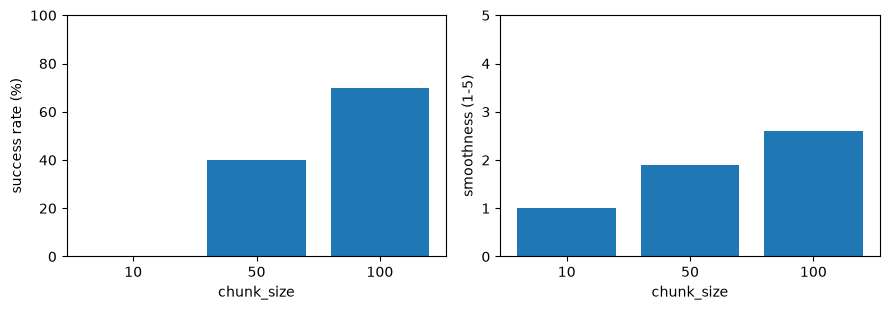

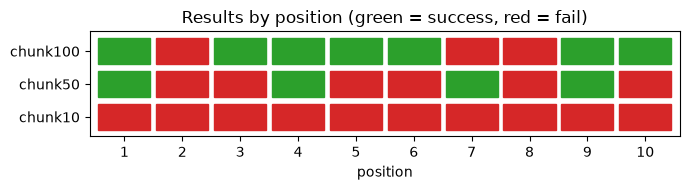

In [25]:
import plt
# 조건별 성공률과 부드러움
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
labels = [str(k) for k in summary.index]
axes[0].bar(labels, summary["success_rate"]); axes[0].set_ylim(0, 100)
axes[0].set_xlabel("chunk_size"); axes[0].set_ylabel("success rate (%)")
axes[1].bar(labels, summary["mean_smooth"]); axes[1].set_ylim(0, 5)
axes[1].set_xlabel("chunk_size"); axes[1].set_ylabel("smoothness (1-5)")
plt.tight_layout(); plt.show()

# 위치별 성공/실패 (행 = chunk_size, 열 = 물체 위치)
fig, ax = plt.subplots(figsize=(7, 2.0))
for row, k in enumerate(CHUNK_SIZES):
    for r in results[k]:
        c = "tab:green" if r["success"] else ("tab:red" if r["success"] is False else "lightgray")
        ax.add_patch(plt.Rectangle((r["position"] - 0.45, row - 0.4), 0.9, 0.8, color=c))
ax.set_xlim(0.4, 10.6); ax.set_ylim(-0.6, len(CHUNK_SIZES) - 0.4)
ax.set_xticks(range(1, 11)); ax.set_yticks(range(len(CHUNK_SIZES)))
ax.set_yticklabels([f"chunk{k}" for k in CHUNK_SIZES]); ax.set_xlabel("position")
ax.set_title("Results by position (green = success, red = fail)")
plt.tight_layout(); plt.show()

### 3-4. 반응성 테스트
조건별로 3회씩 추가로 시도하되, 로봇이 물체를 향해 움직이기 시작한 직후 **물체를 약 5 cm 옮긴다.** 로봇이 새 위치를 따라가는지 관찰한다. (녹화는 선택, 성공률 집계에는 넣지 않음)

반응성 테스트는 녹화가 필요 없으므로 `--strategy.type=base`로 돌린다. `base`는 `--dataset.*` 대신 `--task="..."`와 `--duration=<초>`를 받는다.

`[작성]` 아래 `reactivity`를 채운다.

In [21]:
reactivity = {
    10: [
        {"trial": 0, "followed": False, "note": "시작 지점에서 계속 떨리고 이동하지 않음"},
        {"trial": 1, "followed": False, "note": "시작 지점에서 계속 떨리고 이동하지 않음"},
        {"trial": 2, "followed": False, "note": "시작 지점에서 계속 떨리고 이동하지 않음"}
        ],
    50: [
        {"trial": 0, "followed": True, "note": ""},
        {"trial": 1, "followed": True, "note": ""},
        {"trial": 2, "followed": True, "note": ""}
        ],
    100: [
        {"trial": 0, "followed": True, "note": ""},
        {"trial": 1, "followed": True, "note": ""},
        {"trial": 2, "followed": True, "note": ""}
        ],
}
react_df = pd.concat([pd.DataFrame(v).assign(chunk_size=k) for k, v in reactivity.items()], ignore_index=True)
print(react_df.groupby("chunk_size")["followed"].apply(lambda s: f"{int(s.fillna(False).sum())}/3"))
react_df

chunk_size
10     0/3
50     3/3
100    3/3
Name: followed, dtype: str


,trial,followed,note,chunk_size
0,0,False,시작 지점에서 계속 떨리고 이동하지 않음,10
1,1,False,시작 지점에서 계속 떨리고 이동하지 않음,10
2,2,False,시작 지점에서 계속 떨리고 이동하지 않음,10
3,0,True,,50
4,1,True,,50
5,2,True,,50
6,0,True,,100
7,1,True,,100
8,2,True,,100


### 3-5. 평가 영상
`[작성]` 웹 뷰어(https://huggingface.co/spaces/lerobot/visualize_dataset)에 평가 데이터셋 repo_id를 넣어 재생되는지 확인한다.
chunk_size에 따른 **동작 차이가 잘 드러나는 장면**을 조건별로 하나씩 GIF로 만들어 `images/`에 올리고 아래에 삽입한다. (예: chunk10의 떨림, chunk100의 청크 경계 튐)

![chunk10](images/hw3_chunk10.gif)
![chunk50](images/hw3_chunk50.gif)
![chunk100](images/hw3_chunk100.gif)

## 4. 고찰
`[작성]` 각 질문에 3~5문장으로 답한다. 가능하면 3절의 수치나 영상 장면을 근거로 든다.

**4-1. 가설 검증** — 성공률이 가장 높은 조건은 무엇이었는가? 1-2의 가설과 비교해, 맞았다면 왜 맞았고 달랐다면 왜 달랐는지 설명하라.
chunk_size 100. 이전 가설에서는 10이 가장 성공률이 높을 것으로 기대했지만, 실제로는 오차 누적이 심해져 움직이지 못하는 결과를 확인할 수 있었다.

**4-2. 짧은 청크의 문제** — chunk_size=10에서 관찰된 동작의 특징(떨림, 머뭇거림, 경로 이탈 등)을 compounding error 개념으로 설명하라.
모델은 현재 관측을 바탕으로 다음 행동을 예측한다. 하지만 예측된 행동에 작은 오차가 포함되면 로봇의 실제 위치가 예상과 달라진다.
다음 관측과 예측은 이미 오차가 발생한 상태가 기준이 되어버린다. 관측 주기가 짧기 때문에 이러한 과정이 다수 반복되고, 이게 문제로 이어질 수 있다.

**4-3. 긴 청크의 대가** — chunk_size=100에서 청크가 바뀌는 순간 동작이 끊기거나 튀는 현상이 있었는가? 반응성 테스트 결과와 함께 설명하라.
실제로 chunk_size 50부터는 청크가 바뀌는 순간 팔이 튀는 현상이 눈에 띄게 발생했다.
반응성 테스트에서도 차이는 있었다. 팔이 움직이는 사이에 물체의 위치가 옮겨졌을 때, chunk_size 100이 50보다는 느리게 반응했다.

**4-4. 오프라인 손실과 실제 성능** — 2-3의 `l1_loss`가 낮은 조건이 실로봇 성공률도 높았는가? 그렇지 않다면 이유는 무엇이라고 생각하는가?
l1_loss 수치는 chunk_size 10이 가장 낮았지만 성공률도 가장 낮았다.
l1_loss는 예측값과 정답값 사이의 평균 절대 오차를 의미하는데, 학습을 진행하며 오차를 줄였다고 하여도 Sim-to-Real 문제는 예측할 수 없기 때문이다.

**4-5. 내 태스크에 맞는 chunk_size** — 본인 태스크의 길이와 정밀도 요구 수준을 고려할 때 어떤 chunk_size가 적합한가? 실험하지 않은 값(예: 30)을 제안해도 된다.
실험 결과 chunk_size 100이 성공률은 높았다. 50에서는 관측 주기가 짧아 물체를 잡는데 실패했을 경우 compounding error로 목표 주변에서 반복적으로 떨림이 생겼다.
50보다는 크고 100보다는 작은 값이 성공률을 높일 수도 있겠으나, 태스크 특성상 주변 환경 변화에 빠르게 대응할 필요가 없으므로 100보다 큰 값으로 잡는게 유리해보인다. (e.g. 150 또는 200)

## 5. Temporal ensemble
chunk_size=100 정책을 그대로 두고 추론 방식만 바꿔, 매 스텝 추론하며 겹치는 예측을 가중 평균한다. 재학습은 필요 없다.

```bash
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=knight7024/act_pick_and_place_hair_roll_final_chunk100 \
  --policy.n_action_steps=1 \
  --policy.temporal_ensemble_coeff=0.01 \
  --policy.device=cuda \
  --robot.type=so101_follower \
  --robot.port=/dev/so101_follower \
  --robot.id=follower \
  --robot.cameras='{
      top: {type: opencv, index_or_path: /dev/cam_back, width: 320, height: 240, fps: 30, fourcc: MJPG, backend: V4L2},
      wrist: {type: opencv, index_or_path: /dev/cam_front, width: 320, height: 240, fps: 30, fourcc: MJPG, backend: V4L2},
  }' \
  --teleop.type=so101_leader \
  --teleop.port=/dev/so101_leader \
  --teleop.id=leader \
  --dataset.repo_id=knight7024/rollout_act_pick_and_place_hair_roll_final_chunk100_te \
  --dataset.single_task="pick a hair roll and place into a box" \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=60 \
  --dataset.reset_time_s=5 \
  --display_data=true
```

> `lerobot-rollout`은 `--policy.path`로 불러온 설정 위에 `--policy.*` 값을 덮어쓴다. ACT는 `temporal_ensemble_coeff`를 설정하면 `n_action_steps=1`이어야 하며, 다른 값이면 시작할 때 오류를 낸다.

`[작성]` 3-1과 같은 위치·순서로 10회 평가하고 chunk100 결과와 성공률·부드러움·추론 지연을 비교한다. 3~5문장.
성공률: 70% -> 20% 감소
부드러움/추론 지연: 청크마다 발생하는 튐 현상 없이 목표 위치까지 부드럽게 이동
동작은 부드러워졌으나 성공률은 오히려 낮아졌다. 또한 목표 위치에서 실패시 그대로 멈춰버리는 현상이 새로 생겨났다.

In [26]:
# 5. Temporal ensemble 결과 입력
TE_EVAL_DATASET = "knight7024/rollout_act_pick_and_place_hair_roll_final_chunk100_te_20261119_024423"   # [작성] Hub에 올라간 이름. 예: f"{HF_USER}/rollout_act_pick-cube_chunk100_te_20261102_100000"
te_results = [
    {"episode": 0, "position": 1, "success": True, "smooth": 5, "note": ""},
    {"episode": 1, "position": 2, "success": False, "smooth": 5, "note": "잘못된 위치를 시도했으나 회복하지 못하고 팔이 멈춰버림"},
    {"episode": 2, "position": 3, "success": False, "smooth": 5, "note": "잘못된 위치를 시도했으나 회복하지 못하고 팔이 멈춰버림"},
    {"episode": 3, "position": 4, "success": False, "smooth": 5, "note": "잘못된 위치를 시도했으나 회복하지 못하고 팔이 멈춰버림"},
    {"episode": 4, "position": 5, "success": False, "smooth": 5, "note": "잘못된 위치를 시도했으나 회복하지 못하고 팔이 멈춰버림"},
    {"episode": 5, "position": 6, "success": True, "smooth": 5, "note": ""},
    {"episode": 6, "position": 7, "success": False, "smooth": 5, "note": "잘못된 위치를 시도했으나 회복하지 못하고 팔이 멈춰버림"},
    {"episode": 7, "position": 8, "success": False, "smooth": 5, "note": "잘못된 위치를 시도했으나 회복하지 못하고 팔이 멈춰버림"},
    {"episode": 8, "position": 9, "success": False, "smooth": 5, "note": "잘못된 위치를 시도했으나 회복하지 못하고 팔이 멈춰버림"},
    {"episode": 9, "position": 10, "success": False, "smooth": 5, "note": "잘못된 위치를 시도했으나 회복하지 못하고 팔이 멈춰버림"},
]

te_info = load_json(TE_EVAL_DATASET, "meta/info.json", repo_type="dataset") if TE_EVAL_DATASET else None
if te_info:
    n_ep = te_info.get("total_episodes")
    print(f"temporal ensemble 에피소드 {n_ep}개 ->", "통과" if n_ep == 10 else f"불일치 ({n_ep}개)")

te_df = pd.DataFrame(te_results)
if te_df["success"].notna().all():
    print(f"temporal ensemble 성공률: {te_df['success'].astype(float).mean()*100:.0f}%, 부드러움 평균: {te_df['smooth'].mean():.1f}")
    print(f"chunk100 성공률        : {summary.loc[100, 'success_rate']:.0f}%, 부드러움 평균: {summary.loc[100, 'mean_smooth']:.1f}")
else:
    print("te_results를 실제 결과로 채울 것")

temporal ensemble 에피소드 10개 -> 통과
temporal ensemble 성공률: 20%, 부드러움 평균: 5.0
chunk100 성공률        : 70%, 부드러움 평균: 2.6


## 제출 전 체크리스트
아래 셀을 실행해 모든 항목이 통과하는지 확인한 뒤 커밋한다.

In [29]:
def repo_ok(rid, rtype):
    try:
        api.list_repo_files(rid, repo_type=rtype); return True
    except Exception:
        return False

def file_ok(rid, fname, rtype):
    try:
        hf_hub_download(rid, fname, repo_type=rtype); return True
    except Exception:
        return False

check_items = {
    # "LeRobot 0.6.x 환경": bool(LEROBOT_VERSION) and LEROBOT_VERSION.startswith("0.6."),
    "학습 데이터셋 접근 가능 (public)": repo_ok(TRAIN_DATASET, "dataset"),
    "평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)": all(
        r.split("/", 1)[-1].startswith("rollout_") for r in [*EVAL_DATASETS.values(), TE_EVAL_DATASET] if r),
}
for k in CHUNK_SIZES:
    check_items[f"chunk{k} 정책 업로드됨 (config.json, model.safetensors)"] = (
        file_ok(POLICY_REPOS[k], "config.json", "model") and file_ok(POLICY_REPOS[k], "model.safetensors", "model"))
    check_items[f"chunk{k} 평가 데이터셋 에피소드 10개"] = bool(eval_infos.get(k)) and eval_infos[k].get("total_episodes") == 10
    check_items[f"chunk{k} 회차별 결과 10개 입력"] = all(r["success"] is not None for r in results[k])
    check_items[f"chunk{k} 실패 회차에 원인 기재"] = all(r["note"].strip() for r in results[k] if r["success"] is False)
check_items["통제 변수 일치 (1-3)"] = all(cfg_df[c].nunique(dropna=False) == 1 for c in ["dataset", "steps", "batch_size", "seed"])
check_items["반응성 테스트 9회 입력"] = all(r["followed"] is not None for v in reactivity.values() for r in v)
check_items["temporal ensemble 평가 데이터셋 에피소드 10개"] = bool(te_info) and te_info.get("total_episodes") == 10
check_items["temporal ensemble 회차별 결과 10개 입력"] = all(r["success"] is not None for r in te_results)
check_items["temporal ensemble 실패 회차에 원인 기재"] = all(r["note"].strip() for r in te_results if r["success"] is False)

for k, v in check_items.items():
    print(("[통과] " if v else "[미흡] ") + k)
print("\n모두 통과" if all(check_items.values()) else "\n미흡 항목을 보완한 뒤 커밋할 것")

[통과] 학습 데이터셋 접근 가능 (public)
[통과] 평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)
[통과] chunk10 정책 업로드됨 (config.json, model.safetensors)
[통과] chunk10 평가 데이터셋 에피소드 10개
[통과] chunk10 회차별 결과 10개 입력
[통과] chunk10 실패 회차에 원인 기재
[통과] chunk50 정책 업로드됨 (config.json, model.safetensors)
[통과] chunk50 평가 데이터셋 에피소드 10개
[통과] chunk50 회차별 결과 10개 입력
[통과] chunk50 실패 회차에 원인 기재
[통과] chunk100 정책 업로드됨 (config.json, model.safetensors)
[통과] chunk100 평가 데이터셋 에피소드 10개
[통과] chunk100 회차별 결과 10개 입력
[통과] chunk100 실패 회차에 원인 기재
[통과] 통제 변수 일치 (1-3)
[통과] 반응성 테스트 9회 입력
[통과] temporal ensemble 평가 데이터셋 에피소드 10개
[통과] temporal ensemble 회차별 결과 10개 입력
[통과] temporal ensemble 실패 회차에 원인 기재

모두 통과
